# Benchmark embedding cho Ontology v4

Notebook này so sánh ba mô hình trên cùng 348 chunk Điều luật của `ontology_v4`: BKAI Vietnamese Bi-Encoder, BGE-M3 và Multilingual MPNet. Benchmark chính là vector-only trên Qdrant; Neo4j và LLM không tham gia metric để cô lập ảnh hưởng của embedding model.

In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    path for path in candidates
    if (path / 'labor_rag' / 'evaluation' / 'embedding_benchmark.py').exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from labor_rag.evaluation.embedding_benchmark import (
    DEFAULT_CHUNKS,
    DEFAULT_QUESTIONS,
    DEFAULT_RESULTS,
    MODELS,
    read_jsonl,
)

CHUNKS_PATH = ROOT / 'labor_rag' / 'data' / 'ontology_v4' / 'chunks.jsonl'
QUESTIONS_PATH = ROOT / 'labor_rag' / 'evaluation' / 'benchmark_questions.jsonl'
RESULTS_DIR = ROOT / 'labor_rag' / 'evaluation' / 'results'
SUMMARY_PATH = RESULTS_DIR / 'summary.csv'
PER_QUERY_PATH = RESULTS_DIR / 'per_query_results.jsonl'
print(f'Workspace: {ROOT}')
print(f'Chunks: {CHUNKS_PATH}')
print(f'Results: {RESULTS_DIR}')

d:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Workspace: d:\Work\Learn\HK7_2026-2027\PBL6
Chunks: d:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\data\ontology_v4\chunks.jsonl
Results: d:\Work\Learn\HK7_2026-2027\PBL6\labor_rag\evaluation\results


## 1. Cấu hình model và dữ liệu

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

model_table = pd.DataFrame(MODELS).rename(
    columns={'key': 'key', 'model': 'Hugging Face model', 'collection': 'Qdrant collection'}
)
display(model_table)

chunks = read_jsonl(CHUNKS_PATH)
questions = read_jsonl(QUESTIONS_PATH)
chunk_mapcs = {str(chunk['mapc']) for chunk in chunks}
gold_mapcs = {str(mapc) for question in questions for mapc in question['relevance']}
missing_gold = sorted(gold_mapcs - chunk_mapcs)
validation = pd.DataFrame([{
    'chunk_count': len(chunks),
    'unique_mapc_count': len(chunk_mapcs),
    'question_count': len(questions),
    'gold_mapc_count': len(gold_mapcs),
    'missing_gold_mapc_count': len(missing_gold),
}])
display(validation)
assert len(chunks) == 348, f'Expected 348 chunks, got {len(chunks)}'
assert len(questions) == 30, f'Expected 30 questions, got {len(questions)}'
assert not missing_gold, f'Missing gold MAPC: {missing_gold}'
print('Gold validation: PASS')

,key,Hugging Face model,Qdrant collection
0,bkai,bkai-foundation-models/vietnamese-bi-encoder,legal_v4_bkai
1,bge,BAAI/bge-m3,legal_v4_bge
2,mpnet,sentence-transformers/paraphrase-multilingual-...,legal_v4_mpnet


,chunk_count,unique_mapc_count,question_count,gold_mapc_count,missing_gold_mapc_count
0,348,348,30,42,0


Gold validation: PASS


## 2. Chạy benchmark (tùy chọn)

Thông thường hãy chạy lệnh CLI trước để tải model và tạo ba collection:

```powershell
python -m labor_rag.evaluation.embedding_benchmark --rebuild
```

Nếu muốn chạy trực tiếp từ notebook, đổi `RUN_BENCHMARK` thành `True`. Model load/download không được tính vào latency truy vấn.

In [3]:
RUN_BENCHMARK = False
if RUN_BENCHMARK:
    from labor_rag.evaluation.embedding_benchmark import run_benchmark
    benchmark_output = run_benchmark(
        chunks_path=CHUNKS_PATH,
        questions_path=QUESTIONS_PATH,
        results_dir=RESULTS_DIR,
        top_k=10,
        warmup=3,
        repeats=3,
        rebuild=False,
    )
    print('Benchmark finished.')
else:
    print('Đang dùng kết quả đã có trong evaluation/results/.')

Đang dùng kết quả đã có trong evaluation/results/.


## 3. Bảng metric tổng hợp

In [4]:
if SUMMARY_PATH.exists():
    summary = pd.read_csv(SUMMARY_PATH)
    per_query = pd.DataFrame(read_jsonl(PER_QUERY_PATH)) if PER_QUERY_PATH.exists() else pd.DataFrame()
    display(summary)
else:
    summary = pd.DataFrame()
    per_query = pd.DataFrame()
    print('Chưa có summary.csv. Hãy chạy CLI hoặc đặt RUN_BENCHMARK=True rồi chạy lại các cell.')

,model,model_id,collection,embedding_dimension,query_count,index_action,indexed_points,Recall@1,Recall@5,Recall@10,MRR@10,nDCG@10,mean_latency_ms,median_latency_ms,mean_encode_latency_ms,mean_search_latency_ms,index_time_seconds
0,bkai,bkai-foundation-models/vietnamese-bi-encoder,legal_v4_bkai,768,30,reused,348,0.933333,0.966667,0.966667,0.941667,0.825000,48.5055,46.2060,37.1783,10.9699,0.0
1,bge,BAAI/bge-m3,legal_v4_bge,1024,30,reused,348,0.833333,0.966667,1.000000,0.889815,0.820115,111.7470,110.3399,96.4823,14.8812,0.0
2,mpnet,sentence-transformers/paraphrase-multilingual-...,legal_v4_mpnet,768,30,reused,348,0.700000,0.833333,0.866667,0.753889,0.623132,45.5190,44.3693,35.8443,9.0161,0.0


In [5]:
if not summary.empty:
    metric_columns = [
        'model', 'embedding_dimension', 'Recall@1', 'Recall@5', 'Recall@10',
        'MRR@10', 'nDCG@10', 'mean_latency_ms', 'median_latency_ms',
        'index_time_seconds',
    ]
    display(summary[metric_columns].style.format({
        'Recall@1': '{:.3f}', 'Recall@5': '{:.3f}', 'Recall@10': '{:.3f}',
        'MRR@10': '{:.3f}', 'nDCG@10': '{:.3f}',
        'mean_latency_ms': '{:.2f}', 'median_latency_ms': '{:.2f}',
        'index_time_seconds': '{:.2f}',
    }))
else:
    print('Chưa có dữ liệu metric để hiển thị.')

,model,embedding_dimension,Recall@1,Recall@5,Recall@10,MRR@10,nDCG@10,mean_latency_ms,median_latency_ms,index_time_seconds
0,bkai,768,0.933,0.967,0.967,0.942,0.825,48.51,46.21,0.00
1,bge,1024,0.833,0.967,1.000,0.890,0.820,111.75,110.34,0.00
2,mpnet,768,0.700,0.833,0.867,0.754,0.623,45.52,44.37,0.00


## 4. Recall@k theo model

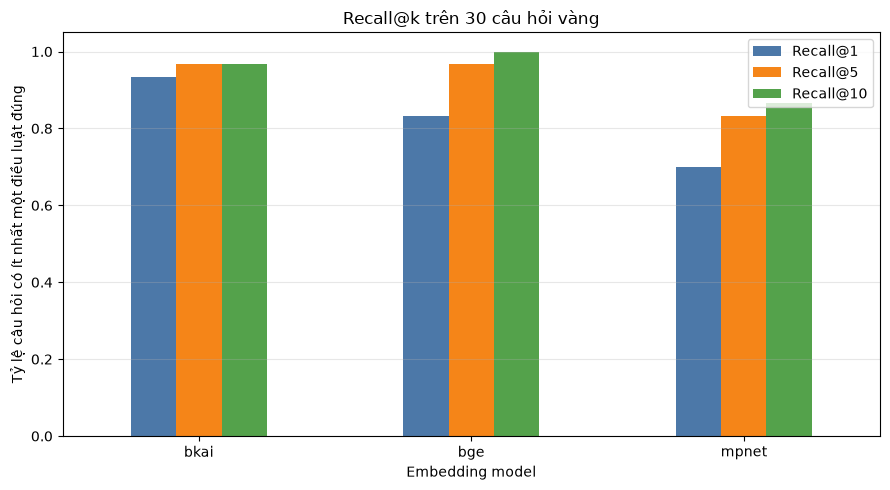

In [6]:
if not summary.empty:
    ax = summary.set_index('model')[['Recall@1', 'Recall@5', 'Recall@10']].plot(
        kind='bar', figsize=(9, 5), ylim=(0, 1.05), rot=0,
        color=['#4C78A8', '#F58518', '#54A24B'],
    )
    ax.set_title('Recall@k trên 30 câu hỏi vàng')
    ax.set_ylabel('Tỷ lệ câu hỏi có ít nhất một điều luật đúng')
    ax.set_xlabel('Embedding model')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

## 5. MRR và nDCG

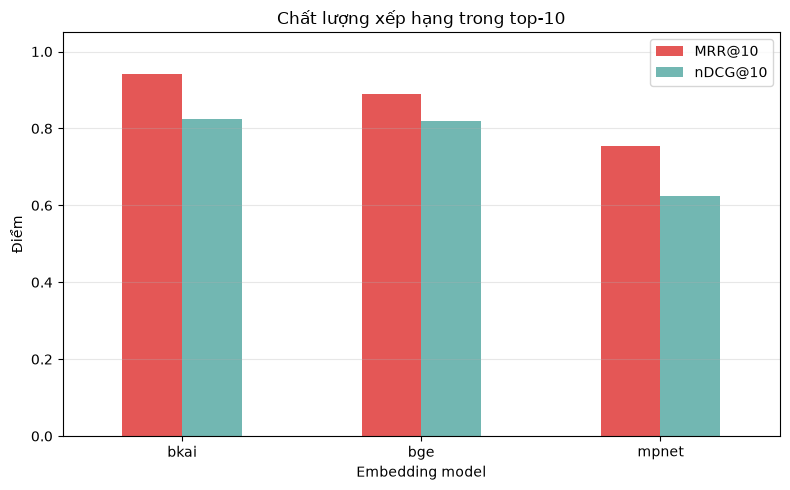

In [7]:
if not summary.empty:
    ax = summary.set_index('model')[['MRR@10', 'nDCG@10']].plot(
        kind='bar', figsize=(8, 5), ylim=(0, 1.05), rot=0,
        color=['#E45756', '#72B7B2'],
    )
    ax.set_title('Chất lượng xếp hạng trong top-10')
    ax.set_ylabel('Điểm')
    ax.set_xlabel('Embedding model')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

## 6. Latency truy vấn

encode_latency_ms        search_latency_ms        latency_ms        
                   mean median              mean median       mean  median
model                                                                     
bge               96.48  94.41             14.88   9.61     111.75  110.34
bkai              37.18  35.61             10.97   8.68      48.51   46.21
mpnet             35.84  34.93              9.02   8.19      45.52   44.37

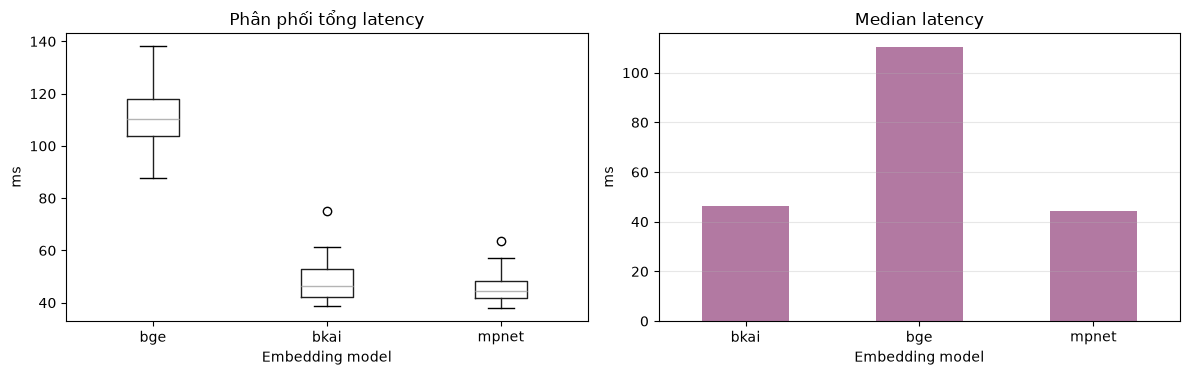

In [8]:
if not per_query.empty:
    latency = per_query[['model', 'question_id', 'latency_ms', 'encode_latency_ms', 'search_latency_ms']].copy()
    display(latency.groupby('model')[['encode_latency_ms', 'search_latency_ms', 'latency_ms']].agg(['mean', 'median']).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    latency.boxplot(column='latency_ms', by='model', ax=axes[0], grid=False)
    axes[0].set_title('Phân phối tổng latency')
    axes[0].set_xlabel('Embedding model')
    axes[0].set_ylabel('ms')
    summary.set_index('model')['median_latency_ms'].plot(kind='bar', ax=axes[1], rot=0, color='#B279A2')
    axes[1].set_title('Median latency')
    axes[1].set_xlabel('Embedding model')
    axes[1].set_ylabel('ms')
    axes[1].grid(axis='y', alpha=0.3)
    fig.suptitle('')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa có per_query_results.jsonl để vẽ latency.')

## 7. Heatmap hit top-1 theo từng câu hỏi

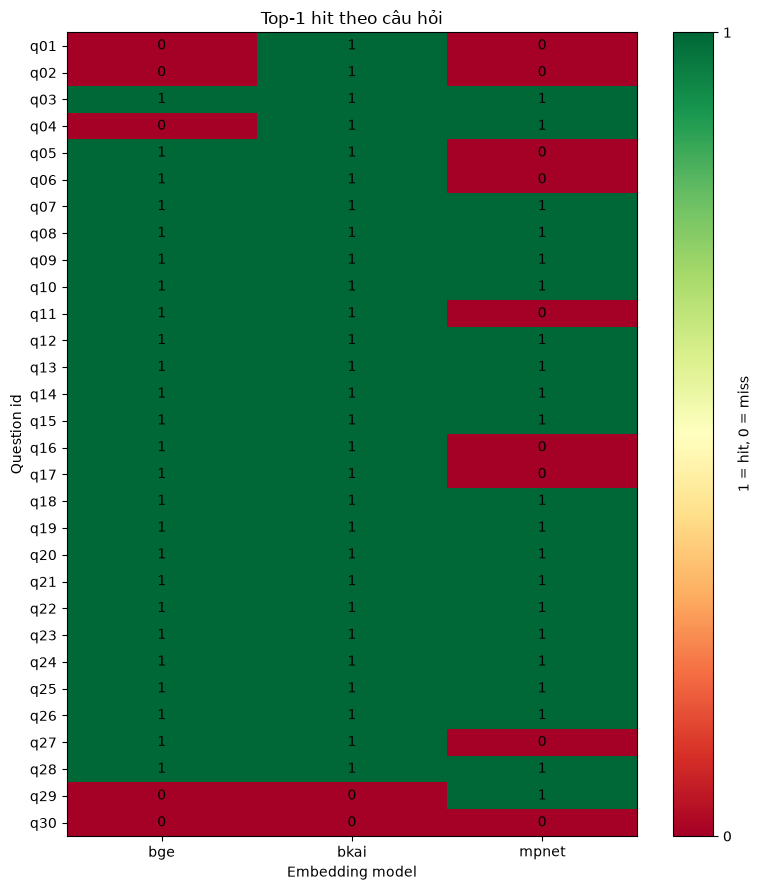

In [9]:
if not per_query.empty:
    top1 = per_query.pivot(index='question_id', columns='model', values='recall_at_1').sort_index()
    fig, ax = plt.subplots(figsize=(8, 9))
    image = ax.imshow(top1.to_numpy(), aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xticks(range(len(top1.columns)), top1.columns)
    ax.set_yticks(range(len(top1.index)), top1.index)
    ax.set_title('Top-1 hit theo câu hỏi')
    ax.set_xlabel('Embedding model')
    ax.set_ylabel('Question id')
    for row_index in range(top1.shape[0]):
        for col_index in range(top1.shape[1]):
            ax.text(col_index, row_index, int(top1.iloc[row_index, col_index]), ha='center', va='center')
    fig.colorbar(image, ax=ax, ticks=[0, 1], label='1 = hit, 0 = miss')
    plt.tight_layout()
    plt.show()

## 8. Ví dụ top-5 của cùng một câu hỏi

In [10]:
if not per_query.empty:
    example_id = sorted(per_query['question_id'].unique())[0]
    example_question = per_query.loc[per_query['question_id'] == example_id, 'question'].iloc[0]
    display(Markdown(f'**{example_id}:** {example_question}'))
    for model_name, row in per_query[per_query['question_id'] == example_id].groupby('model', sort=False):
        results = row.iloc[0]['top_k_results'][:5]
        table = pd.DataFrame(results)
        display(Markdown(f'### {model_name}'))
        display(table[['rank', 'mapc', 'score', 'citation', 'ten']])

**q01:** Người lao động có những quyền cơ bản nào về an toàn, vệ sinh lao động?

### bkai

,rank,mapc,score,citation,ten
0,1,20.5.LQ.6,0.771862,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.7,0.765542,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.69,0.603099,Điều 20.5.LQ.69,"An toàn, vệ sinh lao động đối với người lao độ..."
3,4,20.5.LQ.75,0.598820,Điều 20.5.LQ.75,"Hội đồng an toàn, vệ sinh lao động cơ sở"
4,5,20.5.LQ.17,0.594646,Điều 20.5.LQ.17,Trách nhiệm của người lao động trong việc bảo ...


### bge

,rank,mapc,score,citation,ten
0,1,20.5.LQ.7,0.746529,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.6,0.738639,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.5,0.707939,Điều 20.5.LQ.5,"Nguyên tắc bảo đảm an toàn, vệ sinh lao động"
3,4,20.5.LQ.9,0.695884,Điều 20.5.LQ.9,"Quyền, trách nhiệm của tổ chức công đoàn trong..."
4,5,20.5.LQ.74,0.693797,Điều 20.5.LQ.74,"An toàn, vệ sinh viên"


### mpnet

,rank,mapc,score,citation,ten
0,1,20.5.LQ.7,0.796431,Điều 20.5.LQ.7,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
1,2,20.5.LQ.6,0.784979,Điều 20.5.LQ.6,"Quyền và nghĩa vụ về an toàn, vệ sinh lao động..."
2,3,20.5.LQ.5,0.782458,Điều 20.5.LQ.5,"Nguyên tắc bảo đảm an toàn, vệ sinh lao động"
3,4,20.5.LQ.68,0.778459,Điều 20.5.LQ.68,"An toàn, vệ sinh lao động đối với lao động là ..."
4,5,20.5.LQ.10,0.768045,Điều 20.5.LQ.10,"Quyền, trách nhiệm của công đoàn cơ sở trong c..."


## 9. Kết luận tự động từ kết quả

Không hard-code model thắng. Notebook lấy model tốt nhất trực tiếp từ `summary.csv`; điểm cao hơn là tốt hơn với Recall/MRR/nDCG, còn latency thấp hơn là tốt hơn.

In [11]:
if not summary.empty:
    higher_is_better = ['Recall@1', 'Recall@5', 'Recall@10', 'MRR@10', 'nDCG@10']
    lines = ['### Model đứng đầu theo metric']
    for metric in higher_is_better:
        winner = summary.loc[summary[metric].idxmax(), 'model']
        value = summary.loc[summary[metric].idxmax(), metric]
        lines.append(f'- **{metric}**: `{winner}` ({value:.3f})')
    latency_winner = summary.loc[summary['median_latency_ms'].idxmin(), 'model']
    latency_value = summary['median_latency_ms'].min()
    lines.append(f'- **Median latency thấp nhất**: `{latency_winner}` ({latency_value:.2f} ms)')
    display(Markdown('\n'.join(lines)))
else:
    print('Chưa có kết quả để kết luận.')

### Model đứng đầu theo metric
- **Recall@1**: `bkai` (0.933)
- **Recall@5**: `bkai` (0.967)
- **Recall@10**: `bge` (1.000)
- **MRR@10**: `bkai` (0.942)
- **nDCG@10**: `bkai` (0.825)
- **Median latency thấp nhất**: `mpnet` (44.37 ms)